# NB4 - GeoGraphNet hybrid model and ablations A1-A5

**Run on:** GPU (T4 or P100), **Internet ON** (pretrained EfficientNetV2-S weights; PyTorch Geometric is installed if missing).
**Inputs to add (Kaggle Datasets):** NB1 output (`X16_float16.npy`, `folds.csv`, `labels.npy`, `channel_stats.json`), NB3 output (`graphs_K*_m*.npz`),
and, optionally, NB2 output (`nb2_config.json`, `nb2_probs.npz`) so that the training recipe is copied from NB2 and the B2 comparison (McNemar test) can be made.

**One model, one code path, switches per experiment**

| Exp | graph layer | edge attributes | spectral k-NN edges | fusion | question |
|---|---|---|---|---|---|
| A1 | GCN | no | no | concat | does adjacency help? |
| A2 | GATv2 | no | no | concat | attention vs GCN |
| A2b | GATv2 | yes | no | concat | isolates edge attributes from the operator (proposed addition) |
| A3 | TransformerConv | yes (distance, SAM, boundary) | no | concat | value of edge attributes |
| A4 | TransformerConv | yes | **yes** | concat | **does the spatial-spectral idea help? (A3 vs A4)** |
| A5 | TransformerConv | yes | yes | **gated** | full GeoGraphNet |

**Architecture:** EfficientNetV2-S stem (16 input channels, stages with stride 4, 8, 16, 32) -> 1x1 projections, bilinear upsampling to 64x64, summed into a dense map F;
masked **mean and max pooling of F inside each SLIC region** + 36 static node features -> 2 graph layers (residual + LayerNorm) -> **attention pooling** -> z_GNN;
z_CNN = global pooled CNN vector. Fusion: concat+linear (A1-A4) or gated residual `g * z_CNN + (1-g) * z_GNN` (A5). One cross-entropy loss (label smoothing), one optimizer: the graph gradients flow back into the CNN filters.
The CNN part runs in mixed precision; the graph part runs in float32.

**Same recipe as NB2:** AdamW, cosine annealing, same lr, weight decay, label smoothing, epochs, seed and input size (read from `nb2_config.json` when it is available).
Augmentation (90-degree rotations, flips) is applied **identically to the image, the segmentation map and the node centroids**.
Normalisation statistics (image channels, node features, edge attributes) come from the **training folds only**.
The final K is chosen on **validation Macro-F1 only** (Cell 5). The test fold is used once per model, with the best-validation checkpoint.

**Outputs (/kaggle/working):** `geograph_model.py` (reused by NB6 and NB7), checkpoints `best_<Exp>_K<K>m<m>.pt`, `nb4_metrics.csv`, `nb4_per_class_f1.csv`, `nb4_class_pair_errors.csv`,
`nb4_vs_B2_mcnemar.csv`, `nb4_history.csv`, `nb4_probs.npz`, `nb4_training_curves.png`, `nb4_config.json`.

## Cell 1 - Configuration, GPU check, locate the data from NB1, NB3 (and NB2)

In [1]:
import os, glob, json, time, random, subprocess, sys, re
import numpy as np, pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
try:
    import timm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True); import timm
try:
    import torch_geometric
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch_geometric"], check=True); import torch_geometric

WORK = "/kaggle/working"; os.makedirs(WORK, exist_ok=True)

# ---- recipe: identical to NB2 (copied from nb2_config.json when found) ----
CFG = dict(seed=42, epochs=30, batch_size=128, lr=3e-4, weight_decay=1e-4, label_smoothing=0.1, drop_rate=0.2,
           img_size=64, num_workers=2, backbone="tf_efficientnetv2_s.in21k_ft_in1k",
           D=128, heads=4, layers=2, k_select_epochs=15)
REQUIRE_NB2 = True      # set False only for a quick test without NB2
nb2cfg_path = sorted(glob.glob("/kaggle/input/**/nb2_config.json", recursive=True))
if nb2cfg_path:
    nb2cfg = json.load(open(nb2cfg_path[0]))
    for k in ("seed", "epochs", "batch_size", "lr", "weight_decay", "label_smoothing", "drop_rate", "img_size"):
        if k in nb2cfg: CFG[k] = nb2cfg[k]
    print("Recipe copied from NB2:", {k: CFG[k] for k in ("seed", "epochs", "batch_size", "lr", "weight_decay", "label_smoothing", "img_size")})
else:
    REQ = "NB2 output (nb2_config.json, nb2_probs.npz) is missing from Input: add the NEW NB2 output dataset (needed for the same recipe and McNemar vs B2)."
    if REQUIRE_NB2: raise AssertionError(REQ)
    print("WARNING:", REQ, "Using the default recipe.")

def seed_all(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
seed_all(CFG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None",
      "| torch", torch.__version__, "| PyG", torch_geometric.__version__, "| timm", timm.__version__)

def find(pattern):
    m = sorted(glob.glob(f"/kaggle/input/**/{pattern}", recursive=True))
    return m

x16 = find("X16_float16.npy"); assert x16, "NB1 output not found (X16_float16.npy)"
assert len(x16) == 1, f"Several X16_float16.npy in Input (old NB1 still attached?). Keep only the fixed NB1 dataset: {x16}"
NB1_DIR = os.path.dirname(x16[0])
gfiles = find("graphs_K*_m*.npz"); assert gfiles, "NB3 output not found (graphs_K*_m*.npz)"
GRAPH_FILES = {}
for f in gfiles:
    mm = re.search(r"graphs_K(\d+)_m(\d+)\.npz", os.path.basename(f))
    GRAPH_FILES[(int(mm.group(1)), int(mm.group(2)))] = f
assert len(GRAPH_FILES) == len(gfiles), f"Duplicate graph files in Input (old NB3 still attached?): {gfiles}"
print("NB1_DIR:", NB1_DIR); print("graph configs found:", sorted(GRAPH_FILES))

idx = pd.read_csv(f"{NB1_DIR}/folds.csv")
stats = json.load(open(f"{NB1_DIR}/channel_stats.json"))
y_all = np.load(f"{NB1_DIR}/labels.npy")
try:
    X16 = np.load(f"{NB1_DIR}/X16_float16.npy")
except MemoryError:
    X16 = np.load(f"{NB1_DIR}/X16_float16.npy", mmap_mode="r"); print("X16 loaded as memmap")
assert X16.shape == (len(idx), 16, 64, 64) and (idx["label"].values == y_all).all()
CLASSES = [idx.loc[idx["label"] == i, "class"].iloc[0] for i in range(10)]
FOLDS = idx["fold"].values
_ri = np.sort(np.random.default_rng(0).choice(len(X16), 2000, replace=False))
_ndbi = float(np.asarray(X16[_ri, 15], dtype=np.float32).mean())
print("NDBI mean (random 2000 patches): %.4f  (fixed NB1 = about -0.18; old B12-based = about -0.38)" % _ndbi)
assert _ndbi > -0.25, "OLD X16 detected (B12-based NDBI). Attach the fixed NB1 output only."
print("X16:", X16.shape, "| classes:", CLASSES)

Recipe copied from NB2: {'seed': 42, 'epochs': 30, 'batch_size': 128, 'lr': 0.0003, 'weight_decay': 0.0001, 'label_smoothing': 0.1, 'img_size': 64}
Device: cuda | GPU: Tesla T4 | torch 2.11.0+cu130 | PyG 2.8.1 | timm 1.0.30
NB1_DIR: /kaggle/input/datasets/sudeeptamandal/eurosat-geograph-nb1-v2
graph configs found: [(25, 20), (36, 20)]
NDBI mean (random 2000 patches): -0.1872  (fixed NB1 = about -0.18; old B12-based = about -0.38)
X16: (27000, 16, 64, 64) | classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## Cell 2 - Model module (`geograph_model.py`)

The model, dataset, augmentation and collate code is written to a module so that NB6 (robustness) and NB7 (explainability) import exactly the same code.

In [2]:
MODEL_CODE = r'''
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
import timm
from torch_geometric.nn import GCNConv, GATv2Conv, TransformerConv
from torch_geometric.utils import softmax as pyg_softmax

N_STATIC = 36
CX, CY = 32, 33        # centroid columns in the static node features (see NB3)

EXPERIMENTS = {
    "A1":  dict(kind="gcn",         edge_attr=False, spectral=False, fusion="concat"),
    "A2":  dict(kind="gatv2",       edge_attr=False, spectral=False, fusion="concat"),
    "A2b": dict(kind="gatv2",       edge_attr=True,  spectral=False, fusion="concat"),
    "A3":  dict(kind="transformer", edge_attr=True,  spectral=False, fusion="concat"),
    "A4":  dict(kind="transformer", edge_attr=True,  spectral=True,  fusion="concat"),
    "A5":  dict(kind="transformer", edge_attr=True,  spectral=True,  fusion="gated"),
}


# ---------------------------------------------------------------- numpy side: augmentation, statistics, dataset
def augment_geom(img, seg, node):
    # the same rotation / flips for the image, the segmentation map and the centroids (x, y in [0, 1])
    node = node.copy()
    for _ in range(random.randint(0, 3)):
        img = np.rot90(img, 1, axes=(1, 2)); seg = np.rot90(seg, 1)
        cx, cy = node[:, CX].copy(), node[:, CY].copy()
        node[:, CX], node[:, CY] = cy, 1.0 - cx
    if random.random() < 0.5:                                  # flip along the width axis
        img = np.flip(img, axis=2); seg = np.flip(seg, axis=1); node[:, CX] = 1.0 - node[:, CX]
    if random.random() < 0.5:                                  # flip along the height axis
        img = np.flip(img, axis=1); seg = np.flip(seg, axis=0); node[:, CY] = 1.0 - node[:, CY]
    return np.ascontiguousarray(img), np.ascontiguousarray(seg), node


def graph_stats(G, train_idx, use_spectral):
    # mean/std of node features and edge attributes over the TRAINING graphs only
    n_per, e_per = np.diff(G["node_ptr"]), np.diff(G["edge_ptr"])
    in_tr = np.isin(np.arange(len(n_per)), train_idx)
    nodes = G["node_static"][np.repeat(in_tr, n_per)]
    emask = np.repeat(in_tr, e_per)
    if not use_spectral:
        emask = emask & (G["edge_type"] == 0)
    ea = G["edge_attr"][emask]
    return (nodes.mean(0).astype(np.float32), (nodes.std(0) + 1e-6).astype(np.float32),
            ea.mean(0).astype(np.float32), (ea.std(0) + 1e-6).astype(np.float32))


class GraphDataset(Dataset):
    def __init__(self, indices, G, X16, y, img_mu, img_sd, nstat, use_spectral, augment):
        self.indices = np.asarray(indices, dtype=np.int64)
        self.G, self.X16, self.y = G, X16, y
        self.mu = img_mu.astype(np.float32)[:, None, None]; self.sd = img_sd.astype(np.float32)[:, None, None]
        self.nmu, self.nsd, self.emu, self.esd = nstat
        self.use_spectral, self.augment = use_spectral, augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        r = int(self.indices[i]); G = self.G
        img = (np.asarray(self.X16[r], dtype=np.float32) - self.mu) / (self.sd + 1e-6)
        seg = G["seg"][r].astype(np.int64)
        a, b = int(G["node_ptr"][r]), int(G["node_ptr"][r + 1]); c, d = int(G["edge_ptr"][r]), int(G["edge_ptr"][r + 1])
        node = G["node_static"][a:b].copy()
        ei = G["edge_index"][:, c:d].astype(np.int64); ea = G["edge_attr"][c:d]
        if not self.use_spectral:
            keep = G["edge_type"][c:d] == 0
            ei, ea = ei[:, keep], ea[keep]
        if self.augment:
            img, seg, node = augment_geom(img, seg, node)
        node = (node - self.nmu) / self.nsd
        ea = (ea - self.emu) / self.esd
        return img, seg, node, ei, ea, int(self.y[r])


def collate_numpy(items):
    sizes = [len(it[2]) for it in items]
    offs = np.concatenate([[0], np.cumsum(sizes)]).astype(np.int64)
    return dict(
        x=np.stack([it[0] for it in items]).astype(np.float32),
        node_ids=np.stack([it[1] + offs[i] for i, it in enumerate(items)]).astype(np.int64),
        node_static=np.concatenate([it[2] for it in items]).astype(np.float32),
        edge_index=np.concatenate([it[3] + offs[i] for i, it in enumerate(items)], axis=1).astype(np.int64),
        edge_attr=np.concatenate([it[4] for it in items]).astype(np.float32),
        batch=np.repeat(np.arange(len(items)), sizes).astype(np.int64),
        y=np.array([it[5] for it in items], dtype=np.int64))


def collate(items):
    return {k: torch.from_numpy(v) for k, v in collate_numpy(items).items()}


# ---------------------------------------------------------------- torch side
def pool_regions(fmap, node_ids, n_nodes):
    # masked mean and max pooling of the dense map inside every superpixel (all graphs of the batch at once)
    f = fmap.float()
    D = f.size(1)
    f = f.permute(0, 2, 3, 1).reshape(-1, D)
    ids = node_ids.reshape(-1)
    s = f.new_zeros(n_nodes, D).index_add_(0, ids, f)
    cnt = torch.bincount(ids, minlength=n_nodes).clamp(min=1).unsqueeze(1).to(f.dtype)
    mx = f.new_full((n_nodes, D), float("-inf")).scatter_reduce_(0, ids.unsqueeze(1).expand(-1, D), f,
                                                                  reduce="amax", include_self=True)
    return torch.cat([s / cnt, mx], dim=1)


class AttnPool(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.gate = nn.Linear(d, 1)

    def forward(self, h, batch, B):
        a = pyg_softmax(self.gate(h).squeeze(-1), batch, num_nodes=h.size(0))
        z = h.new_zeros(B, h.size(1)).index_add_(0, batch, h * a.unsqueeze(-1))
        return z, a


class GraphBlock(nn.Module):
    def __init__(self, kind, d, heads, edge_dim, drop):
        super().__init__()
        self.kind = kind
        if kind == "gcn":
            self.conv = GCNConv(d, d)
        elif kind == "gatv2":
            self.conv = GATv2Conv(d, d, heads=heads, concat=False, edge_dim=edge_dim, dropout=drop)
        else:
            self.conv = TransformerConv(d, d, heads=heads, concat=False, edge_dim=edge_dim, dropout=drop)
        self.norm = nn.LayerNorm(d)
        self.drop = nn.Dropout(drop)

    def forward(self, h, ei, ea):
        out = self.conv(h, ei) if self.kind == "gcn" else self.conv(h, ei, ea)
        return self.norm(h + self.drop(F.elu(out)))


class GeoGraphNet(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D = cfg["D"]
        self.cfg, self.img, self.pretrained = cfg, cfg.get("img_size", 64), True
        kw = dict(features_only=True, out_indices=(1, 2, 3, 4), in_chans=16)
        try:
            self.stem = timm.create_model(cfg["backbone"], pretrained=True, **kw)
        except Exception as e:
            print("WARNING: pretrained weights unavailable (%s) -> training the stem from scratch" % type(e).__name__)
            self.stem = timm.create_model(cfg["backbone"], pretrained=False, **kw)
            self.pretrained = False
        chs = self.stem.feature_info.channels()
        self.proj = nn.ModuleList([nn.Conv2d(c, D, 1) for c in chs])
        self.dense_bn = nn.BatchNorm2d(D)
        self.cnn_vec = nn.Sequential(nn.Linear(chs[-1], D), nn.LayerNorm(D))
        self.node_in = nn.Sequential(nn.Linear(2 * D + N_STATIC, D), nn.LayerNorm(D), nn.ELU())
        edge_dim = 3 if cfg["edge_attr"] else None
        self.blocks = nn.ModuleList([GraphBlock(cfg["kind"], D, cfg["heads"], edge_dim, cfg["drop"])
                                     for _ in range(cfg["layers"])])
        self.pool = AttnPool(D)
        if cfg["fusion"] == "gated":
            self.gate = nn.Linear(2 * D, D)
        else:
            self.fuse = nn.Sequential(nn.Linear(2 * D, D), nn.ELU())
        self.drop = nn.Dropout(cfg["drop"])
        self.head = nn.Linear(D, 10)
        self.last_gate, self.last_attn = None, None

    def forward(self, b):
        x = b["x"]
        B = x.size(0)
        xin = x if self.img == 64 else F.interpolate(x, size=(self.img, self.img), mode="bilinear", align_corners=False)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=x.is_cuda):
            feats = self.stem(xin)
            dense = None
            for p, f in zip(self.proj, feats):
                u = F.interpolate(p(f), size=(64, 64), mode="bilinear", align_corners=False)
                dense = u if dense is None else dense + u
            dense = F.relu(self.dense_bn(dense))
            z_cnn = self.cnn_vec(feats[-1].mean(dim=(2, 3)))
        with torch.autocast(device_type="cuda", enabled=False):
            z_cnn = z_cnn.float()
            nodes = pool_regions(dense, b["node_ids"], b["node_static"].size(0))
            h = self.node_in(torch.cat([nodes, b["node_static"]], dim=1))
            ea = b["edge_attr"] if self.cfg["edge_attr"] else None
            for blk in self.blocks:
                h = blk(h, b["edge_index"], ea)
            z_gnn, attn = self.pool(h, b["batch"], B)
            both = torch.cat([z_cnn, z_gnn], dim=1)
            if self.cfg["fusion"] == "gated":
                g = torch.sigmoid(self.gate(both))
                z = g * z_cnn + (1.0 - g) * z_gnn
                self.last_gate = g.mean(dim=1).detach()
            else:
                z = self.fuse(both)
            self.last_attn = attn.detach()
            return self.head(self.drop(z))
'''
open("/kaggle/working/geograph_model.py", "w").write(MODEL_CODE)

import importlib
if "/kaggle/working" not in sys.path:
    sys.path.insert(0, "/kaggle/working")
import geograph_model as gm
importlib.reload(gm)
print("geograph_model.py written and imported | experiments:", list(gm.EXPERIMENTS))

geograph_model.py written and imported | experiments: ['A1', 'A2', 'A2b', 'A3', 'A4', 'A5']


## Cell 3 - Self-check of the geometry code (no GPU needed)

The augmentation must rotate/flip the image, the segmentation map and the node centroids in the same way.
The check recomputes the centroids from the transformed segmentation map and compares them with the transformed centroid features.

In [3]:
def _check_augmentation(n_trials=200):
    rng = np.random.default_rng(0)
    worst = 0.0
    for t in range(n_trials):
        seg = np.kron(rng.integers(0, 6, (4, 4)), np.ones((16, 16), int))
        seg = np.unique(seg, return_inverse=True)[1].reshape(64, 64) + 0           # random blocky map
        seg = np.unique(seg.ravel(), return_inverse=True)[1].reshape(64, 64)
        n = seg.max() + 1
        yy, xx = np.mgrid[0:64, 0:64]
        node = np.zeros((n, gm.N_STATIC), np.float32)
        for k in range(n):
            node[k, gm.CX] = xx[seg == k].mean() / 63.0; node[k, gm.CY] = yy[seg == k].mean() / 63.0
        img = np.broadcast_to(seg[None].astype(np.float32), (16, 64, 64)).copy()
        random.seed(t)
        img2, seg2, node2 = gm.augment_geom(img, seg, node)
        for k in range(n):
            cx = xx[seg2 == k].mean() / 63.0; cy = yy[seg2 == k].mean() / 63.0
            worst = max(worst, abs(cx - node2[k, gm.CX]), abs(cy - node2[k, gm.CY]))
        assert np.array_equal(img2[0], seg2.astype(np.float32)), "image and segmentation map are not transformed together"
    return worst

w = _check_augmentation()
print(f"augmentation check: worst centroid error {w:.2e}")
assert w < 1e-5, "centroids are not transformed consistently with the segmentation map"
print("OK: image, segmentation map and node centroids are augmented consistently")

augmentation check: worst centroid error 4.23e-08
OK: image, segmentation map and node centroids are augmented consistently


## Cell 4 - Splits, graph loading, loaders, metrics, trainer

Splits are identical to NB2 (Phase 1: test fold 0, validation fold 1, train folds 2-4; Phase 2 CV: test fold k, validation fold (k+1) mod 5).
`run_experiment` returns the test metrics (best-validation checkpoint), validation and test probabilities, the training history and, for A5, the mean gate value (weight of the CNN branch).

In [4]:
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, cohen_kappa_score, confusion_matrix)

def make_split(mode="phase1", k=0):
    if mode == "phase1":
        tr = np.where(np.isin(FOLDS, [2, 3, 4]))[0]; va = np.where(FOLDS == 1)[0]; te = np.where(FOLDS == 0)[0]
        st = stats["phase1_train_folds_2_3_4"]
        assert (idx["phase1"].values[tr] == "train").all() and (idx["phase1"].values[va] == "val").all() \
               and (idx["phase1"].values[te] == "test").all()
    else:
        te_f, va_f = k, (k + 1) % 5
        tr = np.where(~np.isin(FOLDS, [te_f, va_f]))[0]; va = np.where(FOLDS == va_f)[0]; te = np.where(FOLDS == te_f)[0]
        st = stats["cv_train_excluding_fold"][str(k)]
    assert not (set(tr) & set(te)) and not (set(va) & set(te)) and not (set(tr) & set(va))
    return dict(mode=mode, k=k, tr=tr, va=va, te=te, mu=np.array(st["mean"], np.float32), sd=np.array(st["std"], np.float32))

_GCACHE = {}
def load_graphs(gcfg):
    if gcfg not in _GCACHE:
        _GCACHE.clear()                                            # keep one graph set in memory
        _GCACHE[gcfg] = dict(np.load(GRAPH_FILES[gcfg]))
        G = _GCACHE[gcfg]; assert len(G["n_nodes"]) == len(idx), "graph file does not match folds.csv"
    return _GCACHE[gcfg]

def _winit(wid):
    s = (torch.initial_seed() + wid) % (2 ** 32); random.seed(s); np.random.seed(s)

def make_loaders(split, G, use_spectral):
    nstat = gm.graph_stats(G, split["tr"], use_spectral)
    bs, nw = CFG["batch_size"], CFG["num_workers"]
    g = torch.Generator(); g.manual_seed(CFG["seed"])
    kw = dict(num_workers=nw, pin_memory=True, worker_init_fn=_winit, persistent_workers=(nw > 0), collate_fn=gm.collate)
    mk = lambda ids, aug: gm.GraphDataset(ids, G, X16, y_all, split["mu"], split["sd"], nstat, use_spectral, aug)
    return (DataLoader(mk(split["tr"], True), batch_size=bs, shuffle=True, generator=g, **kw),
            DataLoader(mk(split["va"], False), batch_size=bs * 2, shuffle=False, **kw),
            DataLoader(mk(split["te"], False), batch_size=bs * 2, shuffle=False, **kw))

def compute_ece(probs, labels, n_bins=15):
    conf, pred = probs.max(axis=1), probs.argmax(axis=1)
    acc = (pred == labels).astype(np.float32); bins = np.linspace(0.0, 1.0, n_bins + 1); ece = 0.0
    for b0, b1 in zip(bins[:-1], bins[1:]):
        m = (conf > b0) & (conf <= b1)
        if m.any(): ece += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(ece)

def evaluate_predictions(probs, labels):
    p = probs.argmax(axis=1)
    return {"Acc": round(accuracy_score(labels, p) * 100, 3),
            "Macro_F1": round(f1_score(labels, p, average="macro", zero_division=0) * 100, 3),
            "Kappa": round(cohen_kappa_score(labels, p), 4), "ECE": round(compute_ece(probs, labels), 4)}

PAIRS = [("AnnualCrop", "PermanentCrop"), ("Residential", "Industrial"), ("HerbaceousVegetation", "Pasture"), ("River", "Highway")]
def class_pair_errors(cm, classes):
    tot = int(cm.sum() - np.trace(cm)); rows = []
    for a, b in PAIRS:
        i, j = classes.index(a), classes.index(b); t = int(cm[i, j] + cm[j, i])
        rows.append({"pair": f"{a} <-> {b}", "a_as_b": int(cm[i, j]), "b_as_a": int(cm[j, i]),
                     "total_confusions": t, "share_of_all_errors_pct": round(100.0 * t / max(tot, 1), 2)})
    return pd.DataFrame(rows)

def to_dev(b):
    return {k: v.to(DEVICE, non_blocking=True) for k, v in b.items()}

@torch.no_grad()
def predict_loader(model, loader):
    model.eval(); P, Y, Gt = [], [], []
    for b in loader:
        b = to_dev(b)
        logits = model(b)
        P.append(torch.softmax(logits.float(), -1).cpu().numpy()); Y.append(b["y"].cpu().numpy())
        if model.last_gate is not None: Gt.append(model.last_gate.cpu().numpy())
    return np.concatenate(P), np.concatenate(Y), (np.concatenate(Gt) if Gt else None)

@torch.no_grad()
def profile_model(model, loader, reps=10):
    model.eval()
    b = to_dev(next(iter(loader)))
    n = b["x"].size(0)
    gflops = float("nan")
    try:
        from torch.utils.flop_counter import FlopCounterMode
        b1 = to_dev(gm.collate([loader.dataset[0]]))
        with FlopCounterMode(display=False) as fc: model(b1)
        gflops = fc.get_total_flops() / 1e9
    except Exception as e:
        print("FLOP counting unavailable:", type(e).__name__)
    for _ in range(3): model(b)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(reps): model(b)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return gflops, (time.time() - t) * 1000.0 / (n * reps)

def make_scaler(enabled):
    try: return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError): return torch.cuda.amp.GradScaler(enabled=enabled)

def run_experiment(code, split, gcfg, epochs=None, tag=""):
    epochs = epochs or CFG["epochs"]
    spec = gm.EXPERIMENTS[code]
    seed_all(CFG["seed"])
    G = load_graphs(gcfg)
    tr_dl, va_dl, te_dl = make_loaders(split, G, spec["spectral"])
    mcfg = dict(spec, D=CFG["D"], heads=CFG["heads"], layers=CFG["layers"], drop=CFG["drop_rate"],
                backbone=CFG["backbone"], img_size=CFG["img_size"])
    model = gm.GeoGraphNet(mcfg).to(DEVICE)
    params_m = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    crit = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
    use_amp = DEVICE.type == "cuda"; scaler = make_scaler(use_amp)
    name = f"{code}_K{gcfg[0]}m{gcfg[1]}{tag}"
    ckpt = f"{WORK}/best_{name}.pt"
    best, best_ep, hist, t0 = -1.0, 0, [], time.time()
    for ep in range(1, epochs + 1):
        model.train(); tl = 0.0
        for b in tr_dl:
            b = to_dev(b)
            opt.zero_grad(set_to_none=True)
            loss = crit(model(b), b["y"])                          # autocast is handled inside the model (CNN part only)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(b["y"])
        sched.step()
        vp, vy, _ = predict_loader(model, va_dl); vres = evaluate_predictions(vp, vy)
        hist.append({"epoch": ep, "train_loss": tl / len(tr_dl.dataset), "val_acc": vres["Acc"], "val_macro_f1": vres["Macro_F1"], "val_ece": vres["ECE"]})
        if vres["Macro_F1"] > best:
            best, best_ep = vres["Macro_F1"], ep; torch.save(model.state_dict(), ckpt)
        if ep == 1 or ep % 5 == 0 or ep == epochs:
            print(f"[{name}] Ep {ep:02d}/{epochs} | loss {tl/len(tr_dl.dataset):.4f} | val F1 {vres['Macro_F1']:.2f}% | best {best:.2f}% (ep {best_ep}) | {(time.time()-t0)/60:.1f} min")
    train_min = (time.time() - t0) / 60.0
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    te_p, te_y, gate = predict_loader(model, te_dl)               # test fold used once
    va_p, va_y, _ = predict_loader(model, va_dl)
    res = evaluate_predictions(te_p, te_y)
    gflops, ms = profile_model(model, te_dl)
    res.update({"Exp": code, "K": gcfg[0], "m": gcfg[1], "layer": spec["kind"], "edge_attr": spec["edge_attr"],
                "spectral_edges": spec["spectral"], "fusion": spec["fusion"], "Params_M": round(params_m, 2),
                "GFLOPs_approx": round(gflops, 3), "Infer_ms": round(ms, 4), "Train_Min": round(train_min, 2),
                "Best_Epoch": best_ep, "Best_Val_F1": best, "Gate_mean_CNN": (round(float(gate.mean()), 4) if gate is not None else None),
                "Pretrained": model.pretrained})
    print(f"--> {name} TEST: Acc={res['Acc']}% | Macro-F1={res['Macro_F1']}% | Kappa={res['Kappa']} | ECE={res['ECE']}\n")
    del model, opt
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return res, te_p, te_y, va_p, va_y, pd.DataFrame(hist)

SPLIT = make_split("phase1")
print({k: len(SPLIT[k]) for k in ("tr", "va", "te")}, "| Phase 1 split OK")

{'tr': 16200, 'va': 5400, 'te': 5400} | Phase 1 split OK


## Cell 5 - Choose the graph configuration (K, compactness) on the validation fold

Trains A3 for a few epochs on each available graph configuration and picks the one with the best **validation** Macro-F1 (the test fold is not used for this choice).
Set `K_SELECT = False` to skip and use `DEFAULT_GRAPH`.

In [5]:
K_SELECT = True
DEFAULT_GRAPH = (25, 20) if (25, 20) in GRAPH_FILES else sorted(GRAPH_FILES)[0]

if K_SELECT and len(GRAPH_FILES) > 1:
    sel = []
    for gcfg in sorted(GRAPH_FILES):
        r, *_ = run_experiment("A3", SPLIT, gcfg, epochs=CFG["k_select_epochs"], tag="_ksel")
        sel.append({"K": gcfg[0], "m": gcfg[1], "Best_Val_F1": r["Best_Val_F1"], "Best_Epoch": r["Best_Epoch"], "Train_Min": r["Train_Min"]})
    sel = pd.DataFrame(sel); display(sel)
    sel.to_csv(f"{WORK}/nb4_k_selection.csv", index=False)
    row = sel.sort_values("Best_Val_F1", ascending=False).iloc[0]
    BEST_GRAPH = (int(row["K"]), int(row["m"]))
else:
    BEST_GRAPH = DEFAULT_GRAPH
print("Graph configuration used for all experiments:", BEST_GRAPH)

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[A3_K25m20_ksel] Ep 01/15 | loss 0.7603 | val F1 96.50% | best 96.50% (ep 1) | 1.3 min
[A3_K25m20_ksel] Ep 05/15 | loss 0.5368 | val F1 98.09% | best 98.09% (ep 5) | 6.4 min
[A3_K25m20_ksel] Ep 10/15 | loss 0.5135 | val F1 98.61% | best 98.61% (ep 10) | 12.8 min
[A3_K25m20_ksel] Ep 15/15 | loss 0.5087 | val F1 98.60% | best 98.62% (ep 13) | 19.1 min
--> A3_K25m20_ksel TEST: Acc=98.796% | Macro-F1=98.731% | Kappa=0.9866 | ECE=0.0765



Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[A3_K36m20_ksel] Ep 01/15 | loss 0.7603 | val F1 96.40% | best 96.40% (ep 1) | 1.3 min
[A3_K36m20_ksel] Ep 05/15 | loss 0.5346 | val F1 97.82% | best 98.09% (ep 3) | 6.4 min
[A3_K36m20_ksel] Ep 10/15 | loss 0.5145 | val F1 98.02% | best 98.52% (ep 8) | 12.8 min
[A3_K36m20_ksel] Ep 15/15 | loss 0.5083 | val F1 98.57% | best 98.57% (ep 13) | 19.3 min
--> A3_K36m20_ksel TEST: Acc=98.852% | Macro-F1=98.787% | Kappa=0.9872 | ECE=0.078



,K,m,Best_Val_F1,Best_Epoch,Train_Min
0,25,20,98.618,13,19.08
1,36,20,98.574,13,19.25


Graph configuration used for all experiments: (25, 20)


## Cell 6 - Train and evaluate the ablation experiments (Phase 1)

`EXPERIMENTS_TO_RUN` is the list to run. Reduced one-week scope: A1, A3, A4, A5. Add A2 and A2b if GPU time allows.
Results are saved after every experiment, so a session timeout does not lose finished runs.

In [6]:
EXPERIMENTS_TO_RUN = ["A1", "A3", "A4", "A5"]       # add "A2", "A2b" if time allows

results, probs, vprobs, hists, gates = [], {}, {}, {}, {}
for code in EXPERIMENTS_TO_RUN:
    res, tp, ty, vp, vy, h = run_experiment(code, SPLIT, BEST_GRAPH)
    results.append(res); probs[code] = tp; vprobs[code] = vp; hists[code] = h; y_te, y_va = ty, vy
    pd.DataFrame(results).to_csv(f"{WORK}/nb4_metrics.csv", index=False)
    pd.concat([h_.assign(Exp=c) for c, h_ in hists.items()]).to_csv(f"{WORK}/nb4_history.csv", index=False)
    np.savez_compressed(f"{WORK}/nb4_probs.npz", y_test=y_te, y_val=y_va,
                        **{f"test_{c}": probs[c] for c in probs}, **{f"val_{c}": vprobs[c] for c in vprobs})
print("done:", EXPERIMENTS_TO_RUN)

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[A1_K25m20] Ep 01/30 | loss 0.7541 | val F1 97.08% | best 97.08% (ep 1) | 1.3 min
[A1_K25m20] Ep 05/30 | loss 0.5389 | val F1 98.15% | best 98.15% (ep 5) | 6.2 min
[A1_K25m20] Ep 10/30 | loss 0.5181 | val F1 97.92% | best 98.22% (ep 9) | 12.4 min
[A1_K25m20] Ep 15/30 | loss 0.5118 | val F1 98.60% | best 98.62% (ep 14) | 18.6 min
[A1_K25m20] Ep 20/30 | loss 0.5069 | val F1 98.80% | best 98.80% (ep 20) | 24.8 min
[A1_K25m20] Ep 25/30 | loss 0.5052 | val F1 98.88% | best 98.88% (ep 25) | 31.0 min
[A1_K25m20] Ep 30/30 | loss 0.5049 | val F1 98.80% | best 98.88% (ep 25) | 37.1 min
--> A1_K25m20 TEST: Acc=98.87% | Macro-F1=98.809% | Kappa=0.9874 | ECE=0.0767



Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[A3_K25m20] Ep 01/30 | loss 0.7602 | val F1 96.46% | best 96.46% (ep 1) | 1.3 min
[A3_K25m20] Ep 05/30 | loss 0.5376 | val F1 97.72% | best 97.87% (ep 3) | 6.3 min
[A3_K25m20] Ep 10/30 | loss 0.5197 | val F1 98.38% | best 98.50% (ep 9) | 12.7 min
[A3_K25m20] Ep 15/30 | loss 0.5127 | val F1 98.72% | best 98.72% (ep 15) | 19.0 min
[A3_K25m20] Ep 20/30 | loss 0.5064 | val F1 98.59% | best 98.72% (ep 15) | 25.3 min
[A3_K25m20] Ep 25/30 | loss 0.5063 | val F1 98.60% | best 98.72% (ep 15) | 31.6 min
[A3_K25m20] Ep 30/30 | loss 0.5051 | val F1 98.64% | best 98.72% (ep 15) | 38.0 min
--> A3_K25m20 TEST: Acc=98.685% | Macro-F1=98.625% | Kappa=0.9854 | ECE=0.0788



Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[A4_K25m20] Ep 01/30 | loss 0.7595 | val F1 96.31% | best 96.31% (ep 1) | 1.3 min
[A4_K25m20] Ep 05/30 | loss 0.5374 | val F1 98.14% | best 98.14% (ep 5) | 6.4 min
[A4_K25m20] Ep 10/30 | loss 0.5204 | val F1 98.23% | best 98.26% (ep 6) | 12.8 min
[A4_K25m20] Ep 15/30 | loss 0.5116 | val F1 98.58% | best 98.66% (ep 14) | 19.2 min
[A4_K25m20] Ep 20/30 | loss 0.5066 | val F1 98.55% | best 98.66% (ep 14) | 25.6 min
[A4_K25m20] Ep 25/30 | loss 0.5055 | val F1 98.55% | best 98.75% (ep 21) | 32.0 min
[A4_K25m20] Ep 30/30 | loss 0.5051 | val F1 98.72% | best 98.75% (ep 29) | 38.4 min
--> A4_K25m20 TEST: Acc=98.852% | Macro-F1=98.786% | Kappa=0.9872 | ECE=0.0773



Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[A5_K25m20] Ep 01/30 | loss 0.7411 | val F1 95.78% | best 95.78% (ep 1) | 1.3 min
[A5_K25m20] Ep 05/30 | loss 0.5386 | val F1 97.70% | best 98.00% (ep 4) | 6.4 min
[A5_K25m20] Ep 10/30 | loss 0.5183 | val F1 98.03% | best 98.16% (ep 8) | 12.8 min
[A5_K25m20] Ep 15/30 | loss 0.5122 | val F1 98.45% | best 98.64% (ep 13) | 19.2 min
[A5_K25m20] Ep 20/30 | loss 0.5077 | val F1 98.61% | best 98.71% (ep 16) | 25.6 min
[A5_K25m20] Ep 25/30 | loss 0.5054 | val F1 98.71% | best 98.76% (ep 23) | 32.0 min
[A5_K25m20] Ep 30/30 | loss 0.5052 | val F1 98.74% | best 98.81% (ep 28) | 38.4 min
--> A5_K25m20 TEST: Acc=98.907% | Macro-F1=98.857% | Kappa=0.9878 | ECE=0.0744

done: ['A1', 'A3', 'A4', 'A5']


## Cell 7 - Results, per-class F1, hard class pairs, comparison with B2 (McNemar), curves

=== Test performance (Phase 1: fold 0, single seed) ===


,Exp,K,m,layer,edge_attr,spectral_edges,fusion,Acc,Macro_F1,Kappa,ECE,Params_M,GFLOPs_approx,Infer_ms,Train_Min,Best_Epoch,Best_Val_F1,Gate_mean_CNN,Pretrained
0,A1,25,20,gcn,False,False,concat,98.870,98.809,0.9874,0.0767,20.06,0.483,0.7196,37.14,25,98.876,NaN,True
1,A3,25,20,transformer,True,False,concat,98.685,98.625,0.9854,0.0788,20.46,0.502,0.7743,37.97,15,98.723,NaN,True
2,A4,25,20,transformer,True,True,concat,98.852,98.786,0.9872,0.0773,20.46,0.503,0.7934,38.38,29,98.755,NaN,True
3,A5,25,20,transformer,True,True,gated,98.907,98.857,0.9878,0.0744,20.46,0.503,0.7944,38.38,28,98.806,0.5029,True


NB2 baselines found: ['B1', 'B2', 'B3']

=== Per-class F1 (%) ===


,A1,A3,A4,A5,B1,B2,B3
AnnualCrop,98.42,98.17,98.42,98.59,98.58,98.16,98.58
Forest,99.58,99.42,99.58,99.67,99.50,99.00,99.59
HerbaceousVegetation,98.25,97.35,98.00,98.33,97.83,96.19,98.49
Highway,98.70,98.79,99.00,99.10,98.30,97.68,99.00
Industrial,99.10,99.30,99.40,99.10,98.70,98.60,99.00
Pasture,97.23,96.72,96.98,97.85,97.50,95.02,97.49
PermanentCrop,98.01,97.80,97.41,97.41,96.71,96.24,98.10
Residential,99.50,99.50,99.67,99.58,99.50,99.00,99.50
River,99.30,99.20,99.40,99.10,98.39,99.00,99.20
SeaLake,100.00,100.00,100.00,99.83,99.83,99.83,99.92



=== Hard class-pair confusions (test fold) ===


,Exp,pair,a_as_b,b_as_a,total_confusions,share_of_all_errors_pct
0,A1,AnnualCrop <-> PermanentCrop,5,5,10,16.39
1,A1,Residential <-> Industrial,2,2,4,6.56
2,A1,HerbaceousVegetation <-> Pasture,4,6,10,16.39
3,A1,River <-> Highway,2,3,5,8.20
0,A3,AnnualCrop <-> PermanentCrop,4,8,12,16.90
1,A3,Residential <-> Industrial,4,1,5,7.04
2,A3,HerbaceousVegetation <-> Pasture,3,15,18,25.35
3,A3,River <-> Highway,1,4,5,7.04
0,A4,AnnualCrop <-> PermanentCrop,5,7,12,19.35
1,A4,Residential <-> Industrial,3,1,4,6.45



=== McNemar exact test on the test fold (single split, single seed: indicative only) ===


,A,B,A_right_B_wrong,A_wrong_B_right,p_value
0,A1,B2,70,22,0.0000
1,A3,B2,69,31,0.0002
2,A4,B2,67,20,0.0000
3,A5,B2,71,21,0.0000
4,A4,A3,35,26,0.3057
5,A5,A4,26,23,0.7754
6,A3,A1,26,36,0.2529


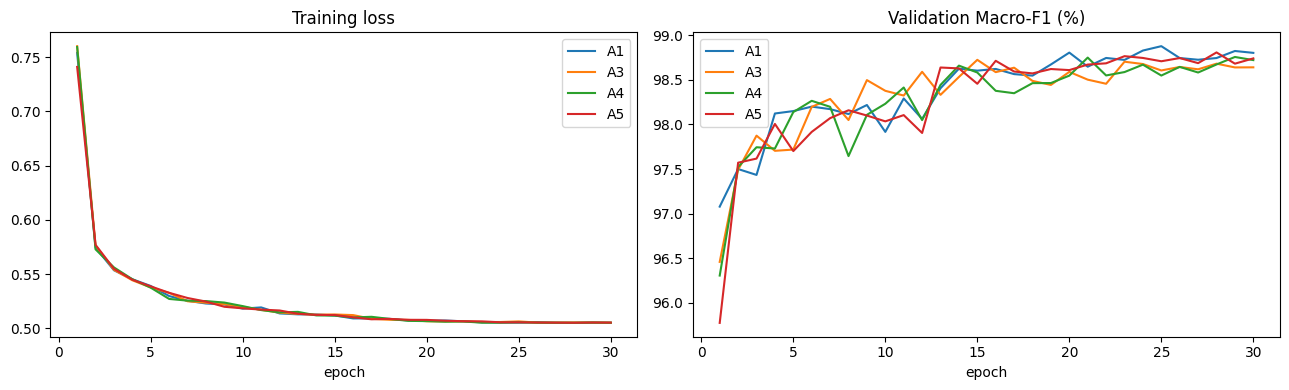

In [7]:
import matplotlib.pyplot as plt
from scipy.stats import binomtest

cols = ["Exp", "K", "m", "layer", "edge_attr", "spectral_edges", "fusion", "Acc", "Macro_F1", "Kappa", "ECE", "Params_M",
        "GFLOPs_approx", "Infer_ms", "Train_Min", "Best_Epoch", "Best_Val_F1", "Gate_mean_CNN", "Pretrained"]
dfm = pd.DataFrame(results)[cols]
print("=== Test performance (Phase 1: fold 0, single seed) ===")
display(dfm)

# optional: NB2 baselines
b_probs, b_y = {}, None
nb2p = sorted(glob.glob("/kaggle/input/**/nb2_probs.npz", recursive=True))
if nb2p:
    z = np.load(nb2p[0]); b_y = z["y_test"]
    b_probs = {k.replace("test_", ""): z[k] for k in z.files if k.startswith("test_")}
    assert (b_y == y_te).all(), "NB2 and NB4 test sets differ"
    print("NB2 baselines found:", list(b_probs))
else:
    assert not REQUIRE_NB2, "nb2_probs.npz not found: add the NEW NB2 output to Input (McNemar vs B2 needs it)."
    print("nb2_probs.npz not found: skipping the comparison with B1-B3")

# per-class F1
per = {c: np.round(f1_score(y_te, probs[c].argmax(1), average=None, labels=list(range(10))) * 100, 2) for c in probs}
for c, p in b_probs.items(): per[c] = np.round(f1_score(y_te, p.argmax(1), average=None, labels=list(range(10))) * 100, 2)
dfc = pd.DataFrame(per, index=CLASSES)
dfc.to_csv(f"{WORK}/nb4_per_class_f1.csv"); print("\n=== Per-class F1 (%) ==="); display(dfc)

# hard class pairs
cms = {c: confusion_matrix(y_te, probs[c].argmax(1), labels=list(range(10))) for c in probs}
for c, p in b_probs.items(): cms[c] = confusion_matrix(y_te, p.argmax(1), labels=list(range(10)))
audit = pd.concat([class_pair_errors(cm, CLASSES).assign(Exp=c) for c, cm in cms.items()])[["Exp", "pair", "a_as_b", "b_as_a", "total_confusions", "share_of_all_errors_pct"]]
audit.to_csv(f"{WORK}/nb4_class_pair_errors.csv", index=False); print("\n=== Hard class-pair confusions (test fold) ==="); display(audit)

# McNemar (exact, two-sided) against B2 and between neighbouring ablation steps
def mcnemar_exact(pa, pb, y):
    ca, cb = pa.argmax(1) == y, pb.argmax(1) == y
    b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
    return b, c, (1.0 if b + c == 0 else float(binomtest(min(b, c), b + c, 0.5).pvalue))
pairs = [(e, "B2") for e in probs if "B2" in b_probs] + [("A4", "A3"), ("A5", "A4"), ("A3", "A1")]
rows = []
for a, b in pairs:
    pa = probs.get(a); pb = probs.get(b, b_probs.get(b))
    if pa is None or pb is None: continue
    n1, n2, p = mcnemar_exact(pa, pb, y_te)
    rows.append({"A": a, "B": b, "A_right_B_wrong": n1, "A_wrong_B_right": n2, "p_value": round(p, 4)})
mc = pd.DataFrame(rows); mc.to_csv(f"{WORK}/nb4_vs_B2_mcnemar.csv", index=False)
print("\n=== McNemar exact test on the test fold (single split, single seed: indicative only) ==="); display(mc)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for c in hists:
    ax[0].plot(hists[c]["epoch"], hists[c]["train_loss"], label=c); ax[1].plot(hists[c]["epoch"], hists[c]["val_macro_f1"], label=c)
ax[0].set_title("Training loss"); ax[1].set_title("Validation Macro-F1 (%)")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(f"{WORK}/nb4_training_curves.png", dpi=130); plt.show()

## Cell 8 - Optional Phase 2: 5-fold cross-validation (set `RUN_CV = True`)

Run this once, after all settings are frozen (graph configuration, epochs, recipe). Each fold: test = fold k, validation = fold (k+1) mod 5, training = the other three,
normalisation statistics from the folds other than k. Heavy: folds x experiments x epochs; split the folds across Kaggle accounts if needed (set `CV_FOLDS`).

In [8]:
RUN_CV = False
CV_FOLDS = [0, 1, 2, 3, 4]
if not RUN_CV:
    print("RUN_CV is False: skipping the 5-fold cross-validation.")
else:
    cv_rows, cv_probs = [], {}
    for k in CV_FOLDS:
        sp = make_split("cv", k)
        for code in EXPERIMENTS_TO_RUN:
            res, tp, ty, vp, vy, h = run_experiment(code, sp, BEST_GRAPH, tag=f"_f{k}")
            res["Fold"] = k; cv_rows.append(res); cv_probs[f"test_{code}_f{k}"] = tp; cv_probs[f"y_test_f{k}"] = ty
            pd.DataFrame(cv_rows).to_csv(f"{WORK}/nb4_cv_results.csv", index=False)
    np.savez_compressed(f"{WORK}/nb4_cv_probs.npz", **cv_probs)
    display(pd.DataFrame(cv_rows).groupby("Exp")[["Acc", "Macro_F1", "Kappa", "ECE"]].agg(["mean", "std"]).round(3))

RUN_CV is False: skipping the 5-fold cross-validation.


## Cell 9 - Save the configuration and list the outputs

In [9]:
cfg_out = dict(CFG)
cfg_out.update({"graph_config_used": list(BEST_GRAPH), "experiments_run": EXPERIMENTS_TO_RUN,
                "definitions": gm.EXPERIMENTS, "split": "Phase 1: train folds 2-4, val fold 1, test fold 0",
                "torch": torch.__version__, "timm": timm.__version__, "torch_geometric": torch_geometric.__version__,
                "note": "GFLOPs exclude scatter/gather operations; latency excludes SLIC and graph construction (cached in NB3)"})
json.dump(cfg_out, open(f"{WORK}/nb4_config.json", "w"), indent=2)
print("files in /kaggle/working:")
for f in sorted(os.listdir(WORK)):
    p = os.path.join(WORK, f)
    if os.path.isfile(p): print(f"  {f:38s} {os.path.getsize(p)/1e6:9.2f} MB")
print("\nNext: Save Version, create a Kaggle Dataset from this output (e.g. eurosat-geograph-nb4). NB6 and NB7 use geograph_model.py and the checkpoints.")

files in /kaggle/working:
  __notebook__.ipynb                          0.20 MB
  best_A1_K25m20.pt                          81.13 MB
  best_A3_K25m20.pt                          82.74 MB
  best_A3_K25m20_ksel.pt                     82.74 MB
  best_A3_K36m20_ksel.pt                     82.74 MB
  best_A4_K25m20.pt                          82.74 MB
  best_A5_K25m20.pt                          82.74 MB
  geograph_model.py                           0.01 MB
  nb4_class_pair_errors.csv                   0.00 MB
  nb4_config.json                             0.00 MB
  nb4_history.csv                             0.01 MB
  nb4_k_selection.csv                         0.00 MB
  nb4_metrics.csv                             0.00 MB
  nb4_per_class_f1.csv                        0.00 MB
  nb4_probs.npz                               1.48 MB
  nb4_training_curves.png                     0.09 MB
  nb4_vs_B2_mcnemar.csv                       0.00 MB

Next: Save Version, create a Kaggle Dataset from this o